In [17]:
import matplotlib.pyplot as plt
import pims, cv2
import trackpy as tp
import pandas as pd
from skimage import filters

In [18]:
@pims.pipeline
def gray(image):
    return image[:, :, 0]  # Take just the red channel

frames = gray(pims.open('C:/Users/Admin/UniBE/data/images/fiji_img/*.jpg'))

c:\Users\Admin\anaconda3\envs\trackpy\Lib\site-packages\pims\image_sequence.py:85: FutureWarning: The plugin infrastructure in `skimage.io` and the parameter `plugin` are deprecated since version 0.25 and will be removed in 0.27 (or later). To avoid this warning, please do not use the parameter `plugin`. Instead, use `imageio` or other I/O packages directly. See also `imread`.
  return imread(filename, **kwargs)


In [19]:
# Read and preprocess a single frame
frame = cv2.imread("C:\\Users\\Admin\\UniBE\\data\\images\\fiji_img\\479_30_mouse_R_01-06-2025_14-43-14_3.jpg", cv2.IMREAD_GRAYSCALE)
blurred = cv2.GaussianBlur(frame, (5, 5), 0)


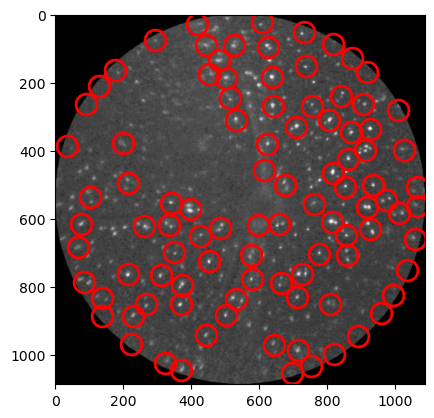

<Axes: >

In [23]:
# Locate blobs in one frame
f = tp.locate(blurred, diameter=51, minmass=5000)  # adjust these parameters
tp.annotate(f, blurred)  # visualize to check detections

[Text(0.5, 0, 'mass'), Text(0, 0.5, 'count')]

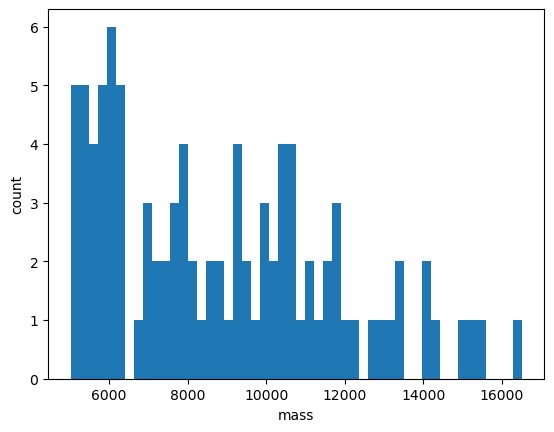

In [24]:
fig, ax = plt.subplots()
ax.hist(f['mass'], bins=50)  # mass --> brightness of detected features

# Optionally, label the axes.
ax.set(xlabel='mass', ylabel='count')

In [25]:
# Locate features in all frames
features = tp.batch(frames[:10], diameter=51, minmass=5000)

Frame 3: 137 features


In [ ]:
# Set a search range – how far a cell can move between frames
search_range = 15    # Adjust based on cell speed
linked = tp.link_df(features, search_range=search_range, memory=1)

Frame 3: 137 trajectories present.


In [27]:
# Only keep trajectories that last at least 4 frames
linked = tp.filter_stubs(linked, threshold=4)
linked

,y,x,mass,size,ecc,signal,raw_mass,ep,frame,particle
frame,,,,,,,,,,
0,345.174904,1038.971488,11499.101328,15.120890,0.427253,22.424446,58924.0,0.000175,0,111
1,349.706970,1035.926962,13119.080127,15.234107,0.191621,39.924631,63210.0,0.000353,1,111
2,336.914538,1034.757677,11996.097297,14.841529,0.269362,41.562565,41506.0,0.000405,2,111
3,333.089892,1026.631396,40639.536140,10.439516,0.440535,152.091296,129815.0,0.000000,3,111


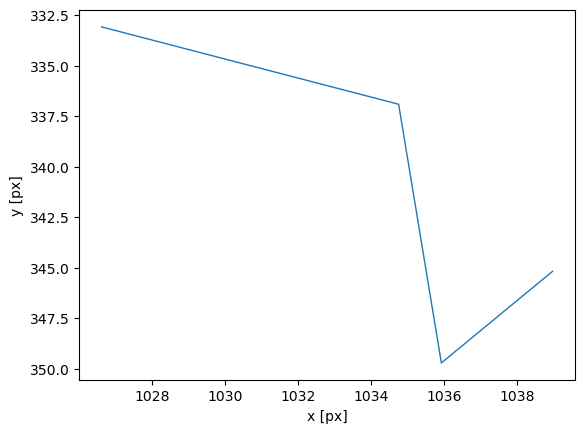

In [28]:
# Plot trajectories
tp.plot_traj(linked)
plt.show()

c:\Users\Admin\anaconda3\envs\trackpy\Lib\site-packages\pims\image_sequence.py:85: FutureWarning: The plugin infrastructure in `skimage.io` and the parameter `plugin` are deprecated since version 0.25 and will be removed in 0.27 (or later). To avoid this warning, please do not use the parameter `plugin`. Instead, use `imageio` or other I/O packages directly. See also `imread`.
  return imread(filename, **kwargs)


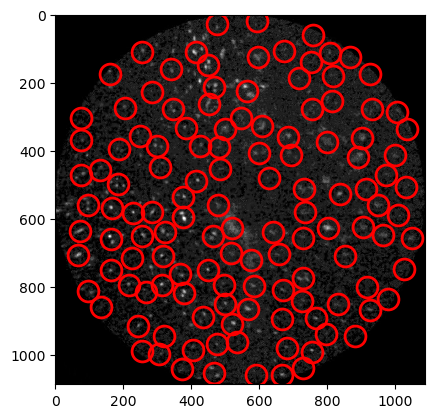

In [29]:
tp.annotate(features[features['frame'] == 2], frames[2])
plt.show()